With smote


With out smote


In [ ]:
"""
Heroin use prediction - model comparison
Dataset : UCI Drug Consumption (Quantified)
Target  : Heroin user (CL2-CL6 = 1), non-user (CL0-CL1 = 0)
Features: personality (NEO-FFI-R, BIS-11, ImpSS) + demographics ONLY
          -> all other drug columns EXCLUDED (poly-drug leakage control)
Models  : Logistic Regression, Random Forest, Naive Bayes, Decision Tree, XGBoost
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def get_models():
    """All models trained on the same SMOTE-balanced train set."""
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                random_state=RANDOM_STATE, n_jobs=-1),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                                random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                 subsample=0.8, colsample_bytree=0.8,
                                 eval_metric='logloss', random_state=RANDOM_STATE),
    }

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test, name=""):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"\n==================== {name} ====================")
    print(f" Accuracy: {acc:.4f}")
    print(f" Balanced Accuracy: {bacc:.4f}")
    print(f" ROC-AUC: {auc:.4f}")
    print(f" PR-AUC: {ap:.4f}  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Non-user (0)', 'User (1)'], digits=3))

    print(" Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")

    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1])
    return {'Model': name, 'Accuracy': acc, 'Balanced Acc': bacc, 'ROC-AUC': auc,
            'PR-AUC': ap, 'Prec(1)': p[1], 'Rec(1)': r[1], 'F1(1)': f[1],
            'F1(0)': f[0], 'Macro F1': (f[0] + f[1]) / 2}

def show_importance(model, feature_names, name):
    """Coefficients for LR, feature_importances_ for tree models."""
    if hasattr(model, 'coef_'):
        imp = pd.DataFrame({'coef': model.coef_[0],
                            'odds_ratio': np.exp(model.coef_[0])}, index=feature_names)
        imp = imp.sort_values('coef', key=abs, ascending=False)
    elif hasattr(model, 'feature_importances_'):
        imp = pd.DataFrame({'importance': model.feature_importances_}, index=feature_names)
        imp = imp.sort_values('importance', ascending=False)
    else:
        return                                   # GaussianNB has neither
    print(f"\n Feature importance - {name}:")
    print(imp.round(3).to_string())

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    results = []
    trained = {}
    for name, model in get_models().items():
        res = train_and_evaluate_model(model, X_train_res, y_train_res,
                                       X_test_s, y_test, name=name)
        results.append(res)
        trained[name] = model

    print("\n\n==================== SUMMARY (test set) ====================")
    summary = pd.DataFrame(results).set_index('Model').sort_values('PR-AUC', ascending=False)
    print(summary.round(3).to_string())

    for name, model in trained.items():
        show_importance(model, X.columns, name)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2334 (1167 users / 1167 non-users)

==================== Logistic Regression ====================
 Accuracy: 0.7021
 Balanced Accuracy: 0.6658
 ROC-AUC: 0.7347
 PR-AUC: 0.2634  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.937     0.713     0.810       501
    User (1)      0.213     0.619     0.317        63

    accuracy                          0.702       564
   macro avg      0.575     0.666     0.563       564
weighted avg      0.856     0.702     0.755       564

 Confusion Matrix:
[[357 144]
 [ 24  39]]

 Sensitivity: 0.619   Specificity: 0.713

==================== Random Forest ====================
 Accuracy: 0.8493
 Balanced Accuracy: 0.6307
 ROC-AUC: 0.7381
 PR-AUC: 0.2808  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.918     0.912     0.915     

In [ ]:
pip install lazypredict

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.0/71.0 kB 3.3 MB/s eta 0:00:00


In [ ]:
# pip install lazypredict
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from lazypredict.Supervised import LazyClassifier
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    # ---------------------- LazyPredict ---------------------- #
    clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    models, predictions = clf.fit(X_train_res, X_test_s, y_train_res, y_test)

    pd.set_option('display.width', 200)
    print("\n==================== LazyPredict Results ====================")
    print(models.round(3).to_string())

    models.to_csv("lazypredict_results.csv")
    print("\nSaved -> lazypredict_results.csv")

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2334 (1167 users / 1167 non-users)

==================== LazyPredict Results ====================
                               Accuracy  Balanced Accuracy  ROC AUC  F1 Score  Precision  Recall  Time Taken
Model                                                                                                       
CalibratedClassifierCV            0.695              0.676    0.732     0.750      0.860   0.695       0.244
LinearSVC                         0.686              0.671    0.732     0.743      0.859   0.686       0.133
LogisticRegression                0.702              0.666    0.735     0.755      0.856   0.702       0.226
RidgeClassifierCV                 0.672              0.663    0.732     0.732      0.856   0.672       0.118
LinearDiscriminantAnalysis        0.672              0.663    0.732     0.732      0.856   0.672       0.329
RidgeClassifier                   0.672             

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score)
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    print(f"\n Accuracy: {accuracy:.4f}")
    print(f" Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f" ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
    print(f" PR-AUC: {average_precision_score(y_test, y_proba):.4f}"
          f"  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                               target_names=['Non-user (0)', 'User (1)'],
                               digits=3, zero_division=0))

    print("\n Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")
    return model

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    # ---------------------- Dummy baselines ---------------------- #
    strategies = ['most_frequent', 'prior', 'stratified', 'uniform', 'constant']

    for strat in strategies:
        print(f"\n==================== DummyClassifier: {strat} ====================")
        if strat == 'constant':
            model = DummyClassifier(strategy='constant', constant=1,
                                    random_state=RANDOM_STATE)
        else:
            model = DummyClassifier(strategy=strat, random_state=RANDOM_STATE)
        train_and_evaluate_model(model, X_train_res, y_train_res, X_test_s, y_test)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2334 (1167 users / 1167 non-users)

==================== DummyClassifier: most_frequent ====================

 Accuracy: 0.8883
 Balanced Accuracy: 0.5000
 ROC-AUC: 0.5000
 PR-AUC: 0.1117  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.888     1.000     0.941       501
    User (1)      0.000     0.000     0.000        63

    accuracy                          0.888       564
   macro avg      0.444     0.500     0.470       564
weighted avg      0.789     0.888     0.836       564


 Confusion Matrix:
[[501   0]
 [ 63   0]]

 Sensitivity: 0.000   Specificity: 1.000

==================== DummyClassifier: prior ====================

 Accuracy: 0.8883
 Balanced Accuracy: 0.5000
 ROC-AUC: 0.5000
 PR-AUC: 0.1117  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.888  

main


In [ ]:
# pip install lightgbm
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score)
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    print(f"\n Accuracy: {accuracy:.4f}")
    print(f" Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f" ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
    print(f" PR-AUC: {average_precision_score(y_test, y_proba):.4f}"
          f"  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                               target_names=['Non-user (0)', 'User (1)'], digits=3))

    print("\n Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")
    return model

def show_importance(model, feature_names):
    imp = pd.DataFrame({'importance': model.feature_importances_}, index=feature_names)
    imp['importance_pct'] = imp['importance'] / imp['importance'].sum()
    imp = imp.sort_values('importance', ascending=False)
    print("\n Feature Importance (split gain count):")
    print(imp.round(3).to_string())

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    print("\n LightGBM Results")
    model = LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                           num_leaves=15, min_child_samples=20,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                           reg_lambda=1.0, verbose=-1, random_state=RANDOM_STATE)
    model = train_and_evaluate_model(model, X_train_res, y_train_res, X_test_s, y_test)
    show_importance(model, X.columns)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2668 (1334 users / 1334 non-users)

 LightGBM Results

 Accuracy: 0.8537
 Balanced Accuracy: 0.6262
 ROC-AUC: 0.7283
 PR-AUC: 0.2783  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.916     0.919     0.918       334
    User (1)      0.341     0.333     0.337        42

    accuracy                          0.854       376
   macro avg      0.629     0.626     0.628       376
weighted avg      0.852     0.854     0.853       376


 Confusion Matrix:
[[307  27]
 [ 28  14]]

 Sensitivity: 0.333   Specificity: 0.919

 Feature Importance (split gain count):
           importance  importance_pct
SS                383           0.122
Oscore            342           0.109
Ascore            332           0.105
Nscore            330           0.105
Education         326           0.103
Impulsive         319           0.101
Cscore           

In [ ]:
# pip install xgboost imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def get_models():
    """All six models, trained on the same SMOTE-balanced train set."""
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000,
                                                  random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=None,
                                                min_samples_leaf=2, n_jobs=-1,
                                                random_state=RANDOM_STATE),
        'SVM (RBF)': SVC(C=1.0, kernel='rbf', gamma='scale', probability=True,
                         random_state=RANDOM_STATE),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                                random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                                 eval_metric='logloss', random_state=RANDOM_STATE),
    }

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test, name=""):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"\n==================== {name} ====================")
    print(f" Accuracy: {acc:.4f}")
    print(f" Balanced Accuracy: {bacc:.4f}")
    print(f" ROC-AUC: {auc:.4f}")
    print(f" PR-AUC: {ap:.4f}  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))

    print(" Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")

    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1],
                                                 zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Balanced Acc': bacc, 'ROC-AUC': auc,
            'PR-AUC': ap, 'Prec(1)': p[1], 'Rec(1)': r[1], 'F1(1)': f[1],
            'F1(0)': f[0], 'Macro F1': (f[0] + f[1]) / 2}, model

def show_importance(model, feature_names, name):
    """Coefficients for linear models, feature_importances_ for tree models."""
    if hasattr(model, 'coef_'):
        imp = pd.DataFrame({'coef': model.coef_[0],
                            'odds_ratio': np.exp(model.coef_[0])}, index=feature_names)
        imp = imp.sort_values('coef', key=abs, ascending=False)
    elif hasattr(model, 'feature_importances_'):
        imp = pd.DataFrame({'importance': model.feature_importances_},
                           index=feature_names)
        imp['importance_pct'] = imp['importance'] / imp['importance'].sum()
        imp = imp.sort_values('importance', ascending=False)
    else:
        return                      # GaussianNB / SVC(RBF) have neither
    print(f"\n Feature Importance - {name}:")
    print(imp.round(3).to_string())

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    results, trained = [], {}
    for name, model in get_models().items():
        res, fitted = train_and_evaluate_model(model, X_train_res, y_train_res,
                                               X_test_s, y_test, name=name)
        results.append(res)
        trained[name] = fitted

    print("\n\n==================== SUMMARY (test set) ====================")
    summary = pd.DataFrame(results).set_index('Model').sort_values('F1(1)',
                                                                  ascending=False)
    print(summary.round(3).to_string())

    for name, model in trained.items():
        show_importance(model, X.columns, name)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2668 (1334 users / 1334 non-users)

==================== Logistic Regression ====================
 Accuracy: 0.7074
 Balanced Accuracy: 0.6896
 ROC-AUC: 0.7294
 PR-AUC: 0.2516  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.944     0.713     0.812       334
    User (1)      0.226     0.667     0.337        42

    accuracy                          0.707       376
   macro avg      0.585     0.690     0.575       376
weighted avg      0.864     0.707     0.759       376

 Confusion Matrix:
[[238  96]
 [ 14  28]]

 Sensitivity: 0.667   Specificity: 0.713

==================== Random Forest ====================
 Accuracy: 0.8511
 Balanced Accuracy: 0.6352
 ROC-AUC: 0.7334
 PR-AUC: 0.3051  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.919     0.913     0.916     

without hyperparemeter


In [ ]:
# pip install xgboost imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_recall_fscore_support)
from imblearn.over_sampling import SMOTE
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def get_models():
    """All six models with library defaults (only random_state fixed for reproducibility)."""
    return {
        'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
        'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(random_state=RANDOM_STATE),
    }

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test, name=""):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"\n==================== {name} ====================")
    print(f" Accuracy: {acc:.4f}")
    print(f" Balanced Accuracy: {bacc:.4f}")
    print(f" ROC-AUC: {auc:.4f}")
    print(f" PR-AUC: {ap:.4f}  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))

    print(" Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")

    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1],
                                                 zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Balanced Acc': bacc, 'ROC-AUC': auc,
            'PR-AUC': ap, 'Prec(1)': p[1], 'Rec(1)': r[1], 'F1(1)': f[1],
            'F1(0)': f[0], 'Macro F1': (f[0] + f[1]) / 2}, model

def show_importance(model, feature_names, name):
    """Coefficients for linear models, feature_importances_ for tree models."""
    if hasattr(model, 'coef_'):
        imp = pd.DataFrame({'coef': model.coef_[0],
                            'odds_ratio': np.exp(model.coef_[0])}, index=feature_names)
        imp = imp.sort_values('coef', key=abs, ascending=False)
    elif hasattr(model, 'feature_importances_'):
        imp = pd.DataFrame({'importance': model.feature_importances_},
                           index=feature_names)
        imp['importance_pct'] = imp['importance'] / imp['importance'].sum()
        imp = imp.sort_values('importance', ascending=False)
    else:
        return                      # GaussianNB / SVC(RBF) have neither
    print(f"\n Feature Importance - {name}:")
    print(imp.round(3).to_string())

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"After SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    results, trained = [], {}
    for name, model in get_models().items():
        res, fitted = train_and_evaluate_model(model, X_train_res, y_train_res,
                                               X_test_s, y_test, name=name)
        results.append(res)
        trained[name] = fitted

    print("\n\n==================== SUMMARY (test set) ====================")
    summary = pd.DataFrame(results).set_index('Model').sort_values('F1(1)',
                                                                  ascending=False)
    print(summary.round(3).to_string())

    for name, model in trained.items():
        show_importance(model, X.columns, name)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12
After SMOTE: train = 2668 (1334 users / 1334 non-users)

==================== Logistic Regression ====================
 Accuracy: 0.7074
 Balanced Accuracy: 0.6896
 ROC-AUC: 0.7294
 PR-AUC: 0.2516  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.944     0.713     0.812       334
    User (1)      0.226     0.667     0.337        42

    accuracy                          0.707       376
   macro avg      0.585     0.690     0.575       376
weighted avg      0.864     0.707     0.759       376

 Confusion Matrix:
[[238  96]
 [ 14  28]]

 Sensitivity: 0.667   Specificity: 0.713

==================== Random Forest ====================
 Accuracy: 0.8484
 Balanced Accuracy: 0.6233
 ROC-AUC: 0.7254
 PR-AUC: 0.2947  (baseline 0.1117)

 Classification Report:
              precision    recall  f1-score   support

Non-user (0)      0.916     0.913     0.915     

In [ ]:
!pip install lime -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
# !pip install shap lime lightgbm imbalanced-learn -q
"""
Explainable AI for the heroin-use pipeline (Colab version - plots show inline)
  1. SHAP global importance (LightGBM + Logistic Regression)
  2. SHAP local explanation (one predicted user)
  3. LIME local explanation for the same case
  4. Explanation stability: SHAP rankings across CV folds (Kendall tau)
  5. Agreement between SHAP / LIME / permutation importance

NOTE ON SMOTE: SHAP is computed on REAL data only. Explaining synthetic
SMOTE points would describe interpolated artefacts, not real respondents.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from scipy.stats import kendalltau
import warnings

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

FEATURES = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity', 'Nscore', 'Escore',
            'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS']


# ---------------------- Data ---------------------- #
def load_data(filename="drug_consumption.csv"):
    df = pd.read_csv(filename)
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    return df[FEATURES], df['target']


def make_lgbm():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                          num_leaves=15, min_child_samples=20, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          verbose=-1, random_state=RANDOM_STATE)


# ---------------------- 1. SHAP global ---------------------- #
def shap_global(model, X_test_df, model_type='tree', tag='lgbm'):
    if model_type == 'tree':
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_test_df)
        if isinstance(sv, list):          # older shap returns [class0, class1]
            sv = sv[1]
    else:                                  # linear model
        explainer = shap.LinearExplainer(model, X_test_df)
        sv = explainer.shap_values(X_test_df)

    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=X_test_df.columns)
    mean_abs = mean_abs.sort_values(ascending=False)
    print(f"\n SHAP global importance ({tag}) - mean |SHAP|:")
    print(mean_abs.round(4).to_string())

    shap.summary_plot(sv, X_test_df, show=False, max_display=12)
    plt.tight_layout(); plt.savefig(f'shap_beeswarm_{tag}.png', dpi=150); plt.show()

    shap.summary_plot(sv, X_test_df, plot_type='bar', show=False, max_display=12)
    plt.tight_layout(); plt.savefig(f'shap_bar_{tag}.png', dpi=150); plt.show()

    top = mean_abs.index[0]
    shap.dependence_plot(top, sv, X_test_df, show=False)
    plt.tight_layout(); plt.savefig(f'shap_dependence_{tag}_{top}.png', dpi=150); plt.show()
    return sv, mean_abs


# ---------------------- 2. SHAP local ---------------------- #
def shap_local(model, X_test_df, sv, idx, tag='lgbm'):
    explainer = shap.TreeExplainer(model)
    base = explainer.expected_value
    if isinstance(base, (list, np.ndarray)):
        base = np.array(base).ravel()[-1]
    exp = shap.Explanation(values=sv[idx], base_values=base,
                           data=X_test_df.iloc[idx].values,
                           feature_names=list(X_test_df.columns))
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.tight_layout(); plt.savefig(f'shap_waterfall_{tag}_case{idx}.png', dpi=150); plt.show()
    print(f"\n Local SHAP (case {idx}), top drivers:")
    print(pd.Series(sv[idx], index=X_test_df.columns)
          .sort_values(key=abs, ascending=False).head(6).round(4).to_string())


# ---------------------- 3. LIME local ---------------------- #
def lime_local(model, X_train_arr, X_test_df, idx):
    explainer = LimeTabularExplainer(X_train_arr, feature_names=list(X_test_df.columns),
                                     class_names=['Non-user', 'User'],
                                     discretize_continuous=True, random_state=RANDOM_STATE)
    exp = explainer.explain_instance(X_test_df.iloc[idx].values,
                                     model.predict_proba, num_features=8)
    print(f"\n LIME explanation (case {idx}):")
    for feat, weight in exp.as_list():
        print(f"   {feat:35s} {weight:+.4f}")
    fig = exp.as_pyplot_figure()
    plt.tight_layout(); plt.savefig(f'lime_case{idx}.png', dpi=150); plt.show()
    exp.show_in_notebook(show_table=True)      # interactive view in Colab
    return dict(exp.as_map()[1])


# ---------------------- 4. SHAP stability across folds ---------------------- #
def shap_stability(X, y, n_splits=5):
    """Do SHAP rankings hold up across folds? Small positive class -> check this."""
    cv = StratifiedKFold(n_splits, shuffle=True, random_state=RANDOM_STATE)
    rankings = []
    for k, (tr, te) in enumerate(cv.split(X, y), 1):
        sc = StandardScaler().fit(X.iloc[tr])
        Xtr = pd.DataFrame(sc.transform(X.iloc[tr]), columns=X.columns)
        Xte = pd.DataFrame(sc.transform(X.iloc[te]), columns=X.columns)
        Xr, yr = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, y.iloc[tr])
        m = make_lgbm().fit(Xr, yr)
        sv = shap.TreeExplainer(m).shap_values(Xte)
        if isinstance(sv, list):
            sv = sv[1]
        rankings.append(pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
                        .rank(ascending=False))
    R = pd.DataFrame(rankings, index=[f'fold{k}' for k in range(1, n_splits + 1)])
    print("\n SHAP rank per fold (1 = most important):")
    print(R.astype(int).to_string())
    print("\n Rank mean / SD across folds:")
    print(pd.DataFrame({'mean_rank': R.mean(), 'sd_rank': R.std()})
          .sort_values('mean_rank').round(2).to_string())

    taus = [kendalltau(R.iloc[i], R.iloc[j]).correlation
            for i in range(n_splits) for j in range(i + 1, n_splits)]
    print(f"\n Pairwise Kendall tau between folds: mean {np.mean(taus):.3f} "
          f"(min {np.min(taus):.3f}, max {np.max(taus):.3f})")

    R.T.plot(kind='bar', figsize=(11, 4), width=0.8)
    plt.ylabel('SHAP rank (1 = most important)'); plt.gca().invert_yaxis()
    plt.title('SHAP rank per fold'); plt.legend(ncol=5, fontsize=8)
    plt.tight_layout(); plt.savefig('shap_rank_stability.png', dpi=150); plt.show()
    return R


# ---------------------- 5. Method agreement ---------------------- #
def method_agreement(model, X_test_df, y_test, shap_rank):
    perm = permutation_importance(model, X_test_df, y_test, n_repeats=30,
                                  random_state=RANDOM_STATE, scoring='average_precision')
    perm_rank = pd.Series(perm.importances_mean, index=X_test_df.columns).rank(ascending=False)
    tau = kendalltau(shap_rank, perm_rank).correlation
    comp = pd.DataFrame({'shap_rank': shap_rank, 'perm_rank': perm_rank}).sort_values('shap_rank')
    print("\n SHAP rank vs permutation-importance rank:")
    print(comp.round(1).to_string())
    print(f" Kendall tau (SHAP vs permutation): {tau:.3f}")

    comp.plot(kind='bar', figsize=(10, 4))
    plt.ylabel('rank (1 = most important)'); plt.gca().invert_yaxis()
    plt.title(f'SHAP vs permutation importance (Kendall tau = {tau:.3f})')
    plt.tight_layout(); plt.savefig('shap_vs_permutation.png', dpi=150); plt.show()


# ---------------------- Main ---------------------- #
def main():
    X, y = load_data()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20,
                                              random_state=RANDOM_STATE, stratify=y)
    sc = StandardScaler().fit(X_tr)
    X_tr_s = pd.DataFrame(sc.transform(X_tr), columns=FEATURES)
    X_te_s = pd.DataFrame(sc.transform(X_te), columns=FEATURES)
    X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr_s, y_tr)

    # --- LightGBM ---
    lgbm = make_lgbm().fit(X_res, y_res)
    sv, mean_abs = shap_global(lgbm, X_te_s, 'tree', tag='lgbm')

    proba = lgbm.predict_proba(X_te_s)[:, 1]
    idx = int(np.argmax(proba))                      # highest-risk test case
    print(f"\n Explaining case {idx} (predicted P(user) = {proba[idx]:.3f}, "
          f"true label = {y_te.iloc[idx]})")
    shap_local(lgbm, X_te_s, sv, idx, tag='lgbm')
    lime_local(lgbm, X_res.values, X_te_s, idx)

    # --- Logistic Regression (linear reference) ---
    lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_res, y_res)
    _, mean_abs_lr = shap_global(lr, X_te_s, 'linear', tag='logreg')
    tau_models = kendalltau(mean_abs.rank(ascending=False),
                            mean_abs_lr.rank(ascending=False)).correlation
    print(f"\n Kendall tau, LightGBM SHAP vs Logistic SHAP ranking: {tau_models:.3f}")

    # --- stability + agreement ---
    shap_stability(X, y)
    method_agreement(lgbm, X_te_s, y_te, mean_abs.rank(ascending=False))

    print("\n Saved plots: shap_beeswarm_*.png, shap_bar_*.png, shap_dependence_*.png, "
          "shap_waterfall_*.png, lime_case*.png, shap_rank_stability.png, "
          "shap_vs_permutation.png")


if __name__ == "__main__":
    main()


 SHAP global importance (lgbm) - mean |SHAP|:
Country      1.3004
Oscore       0.5647
Education    0.4359
Nscore       0.4122
Age          0.4120
SS           0.3791
Impulsive    0.3442
Ascore       0.3239
Gender       0.2805
Cscore       0.2390
Escore       0.1322
Ethnicity    0.0336

 Explaining case 250 (predicted P(user) = 0.929, true label = 1)

 Local SHAP (case 250), top drivers:
Country      0.9148
Cscore       0.5541
Nscore      -0.5292
Oscore       0.4968
Escore       0.4104
Education    0.2256

 LIME explanation (case 250):
   -1.13 < Age <= -0.14                +0.0752
   Nscore <= -0.43                     -0.0493
   SS > 0.93                           +0.0409
   -0.85 < Cscore <= -0.26             +0.0238
   Oscore > 0.86                       +0.0217
   Escore > 0.64                       -0.0196
   Education <= -0.65                  +0.0191
   Impulsive > 0.92                    +0.0181



 SHAP global importance (logreg) - mean |SHAP|:
Country      0.9425
Nscore       0.4498
Gender       0.3642
Oscore       0.3365
SS           0.2335
Education    0.2176
Ascore       0.2147
Impulsive    0.1049
Age          0.0322
Cscore       0.0114
Escore       0.0077
Ethnicity    0.0039

 Kendall tau, LightGBM SHAP vs Logistic SHAP ranking: 1.000

 SHAP rank per fold (1 = most important):
       Age  Gender  Education  Country  Ethnicity  Nscore  Escore  Oscore  Ascore  Cscore  Impulsive  SS
fold1    7       8          2        1         12       4      10       3       9      11          6   5
fold2    3       9          5        1         12       4      11       2       8      10          6   7
fold3    2       9          4        1         12       6      11       7       8      10          3   5
fold4    5       8          2        1         12       7      10       4       9      11          6   3
fold5    4       8          3        1         12       7      10       2       9 


 SHAP global importance (lgbm) - mean |SHAP|:
Country      1.3004
Oscore       0.5647
Education    0.4359
Nscore       0.4122
Age          0.4120
SS           0.3791
Impulsive    0.3442
Ascore       0.3239
Gender       0.2805
Cscore       0.2390
Escore       0.1322
Ethnicity    0.0336


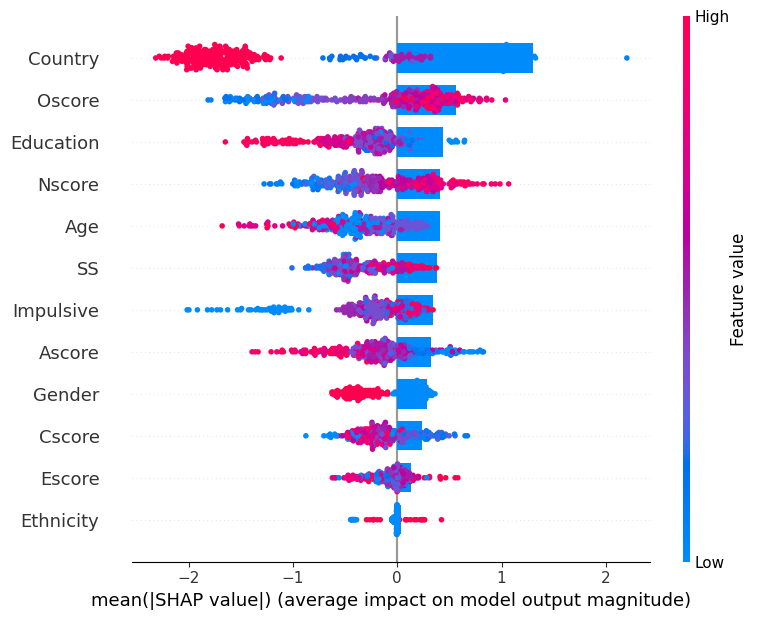

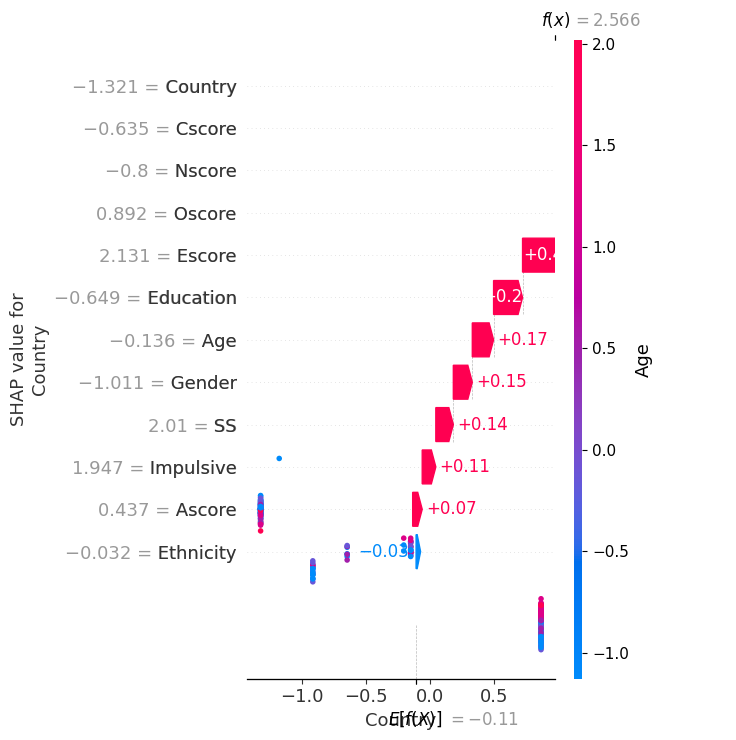

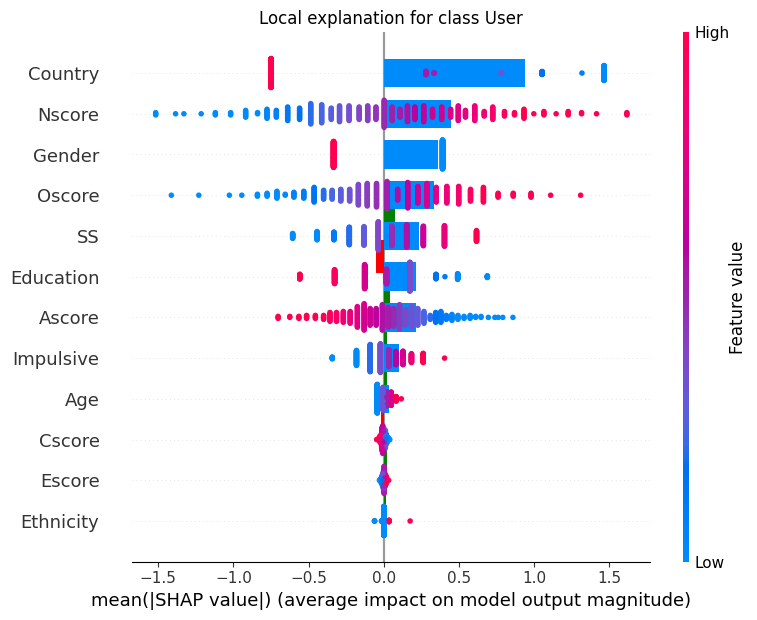

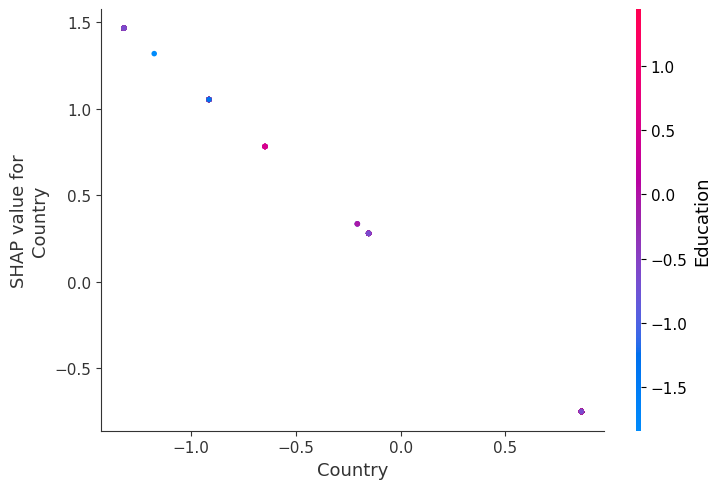

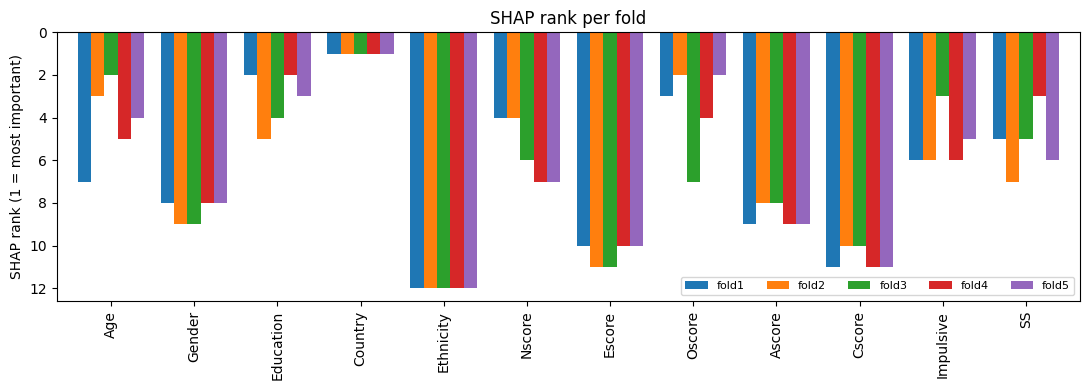

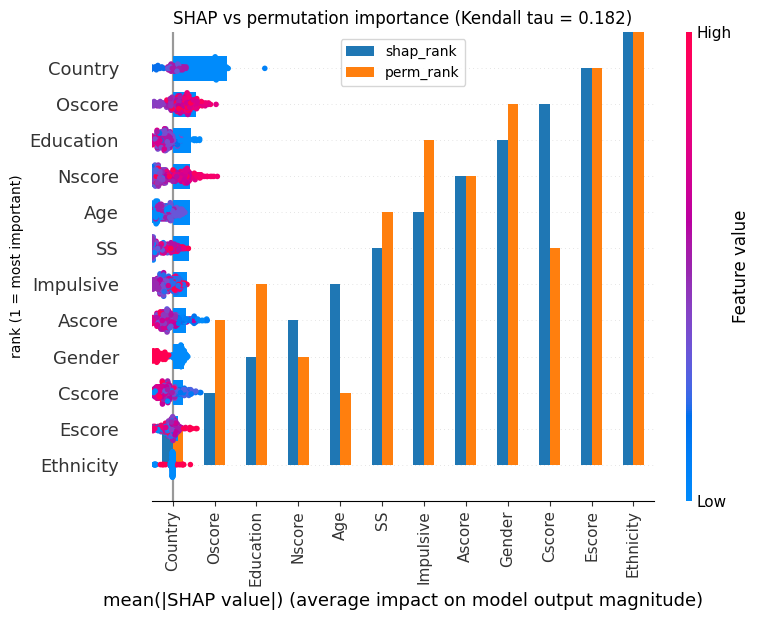

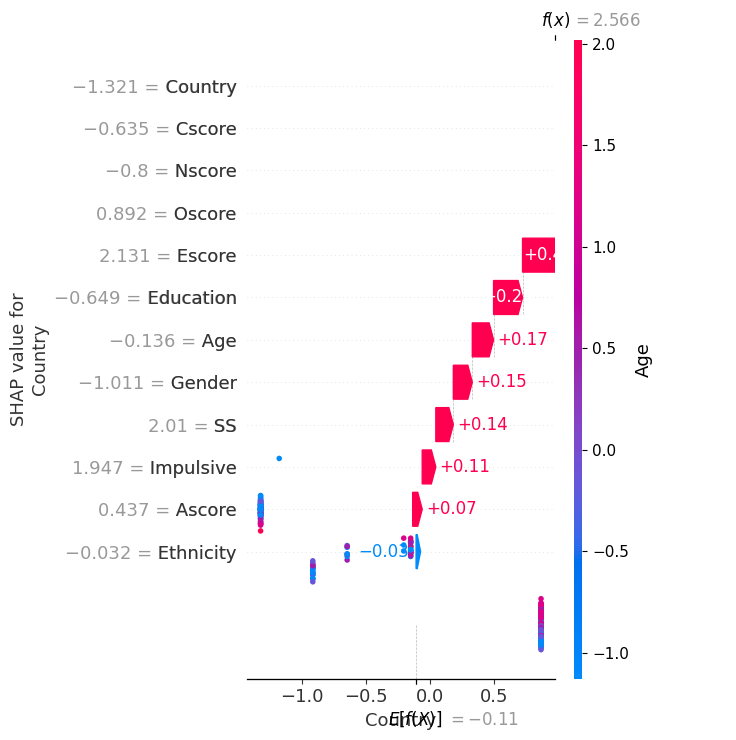

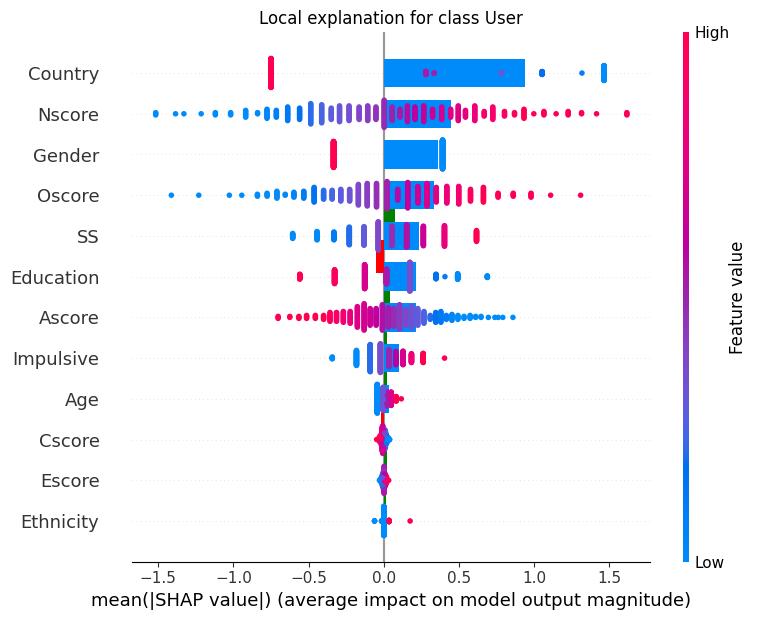

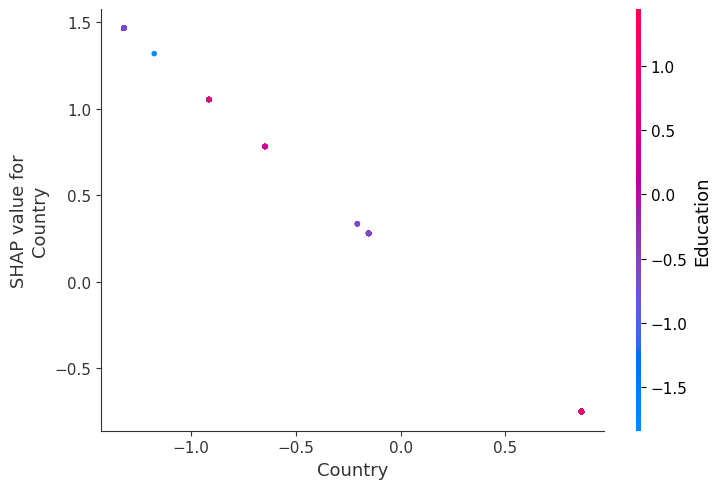

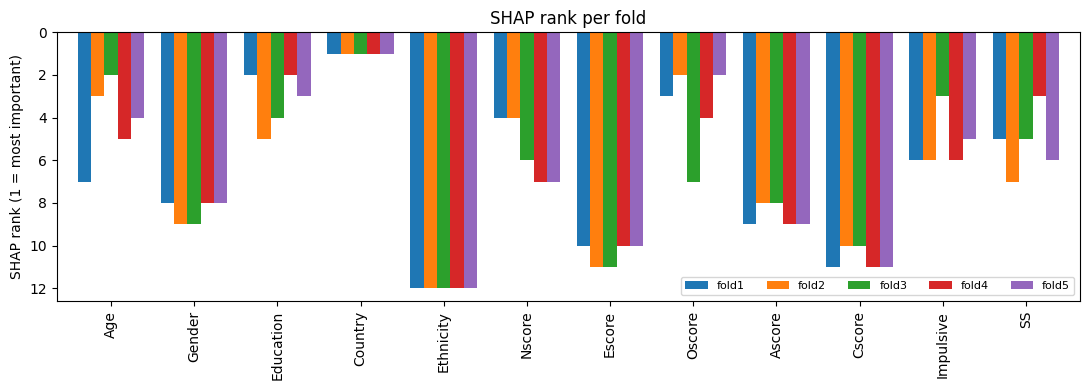

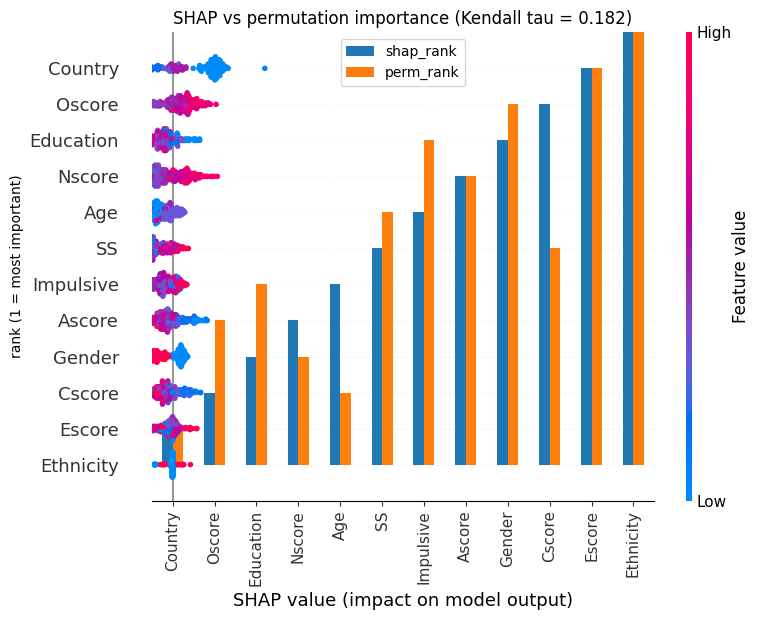

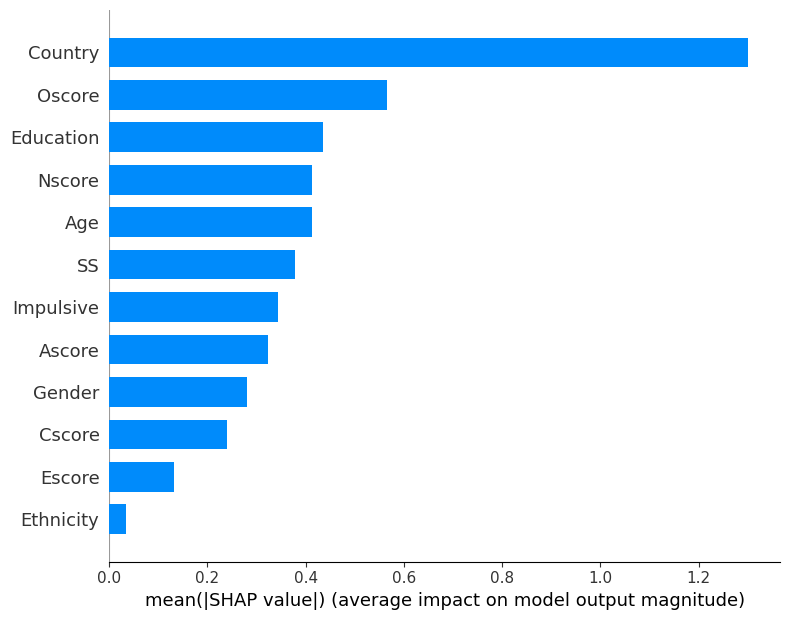

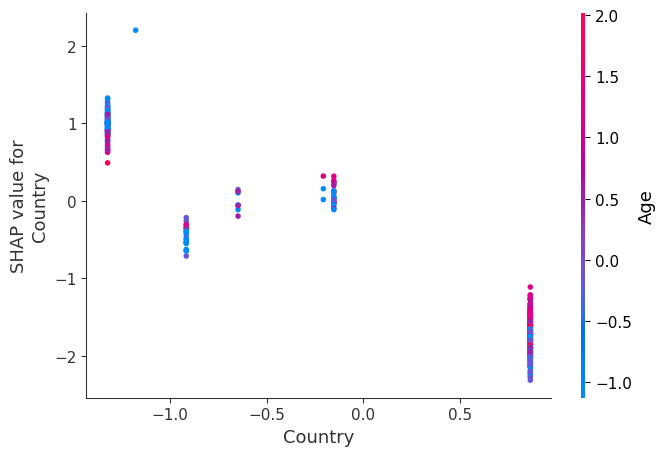


 Explaining case 250: predicted P(user) = 0.929, true label = 1


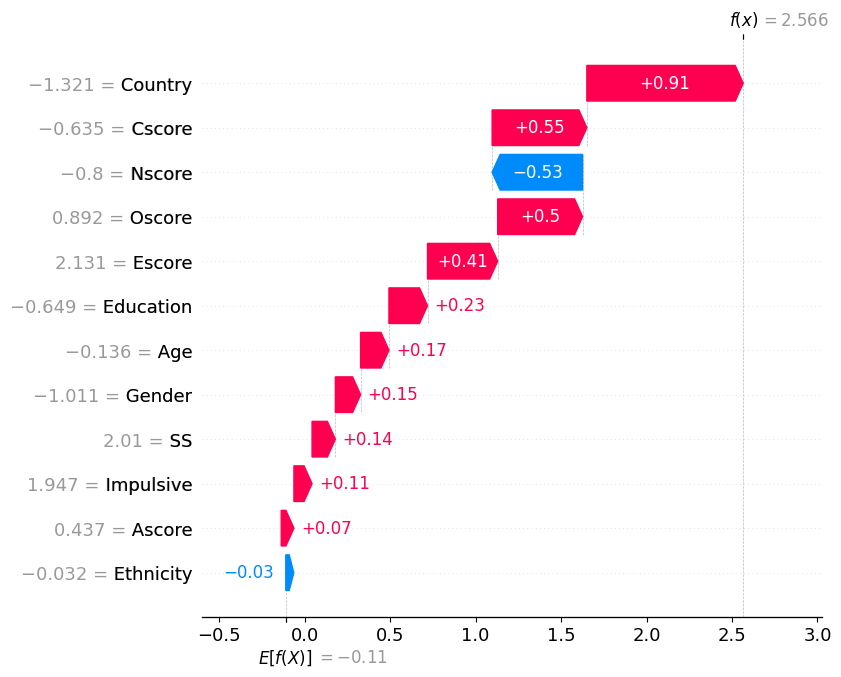


 Local SHAP (case 250), top drivers:
Country      0.9148
Cscore       0.5541
Nscore      -0.5292
Oscore       0.4968
Escore       0.4104
Education    0.2256

 LIME explanation (case 250):
   -1.13 < Age <= -0.14                +0.0752
   Nscore <= -0.43                     -0.0493
   SS > 0.93                           +0.0409
   -0.85 < Cscore <= -0.26             +0.0238
   Oscore > 0.86                       +0.0217
   Escore > 0.64                       -0.0196
   Education <= -0.65                  +0.0191
   Impulsive > 0.92                    +0.0181


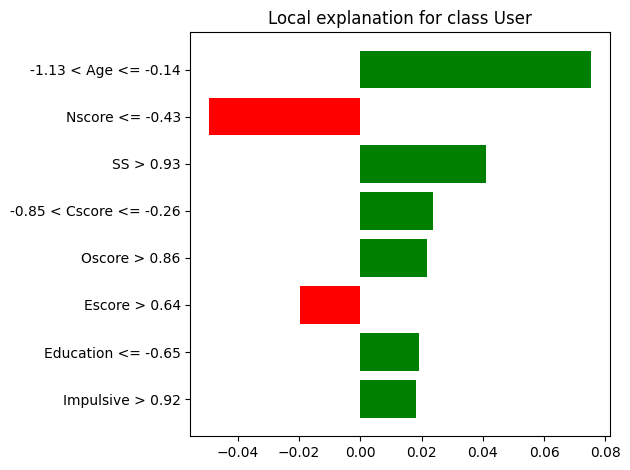


 SHAP global importance (logreg) - mean |SHAP|:
Country      0.9425
Nscore       0.4498
Gender       0.3642
Oscore       0.3365
SS           0.2335
Education    0.2176
Ascore       0.2147
Impulsive    0.1049
Age          0.0322
Cscore       0.0114
Escore       0.0077
Ethnicity    0.0039


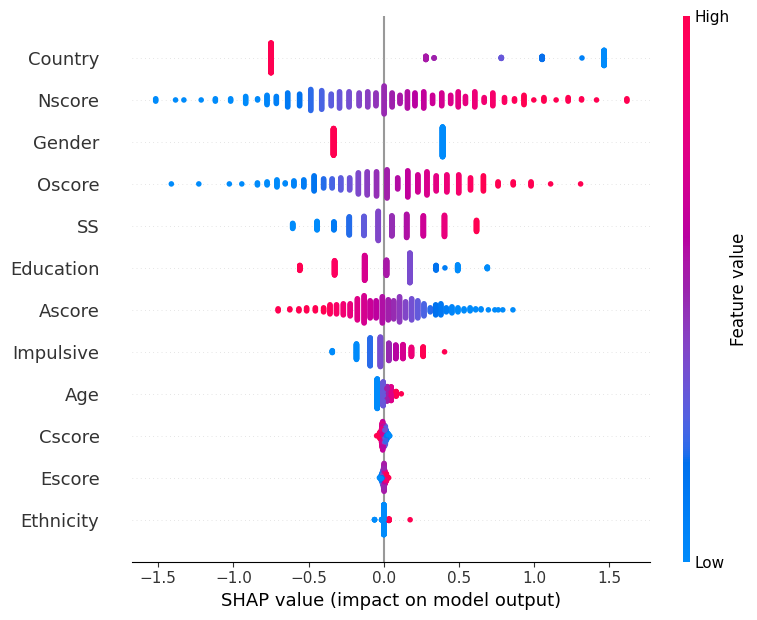

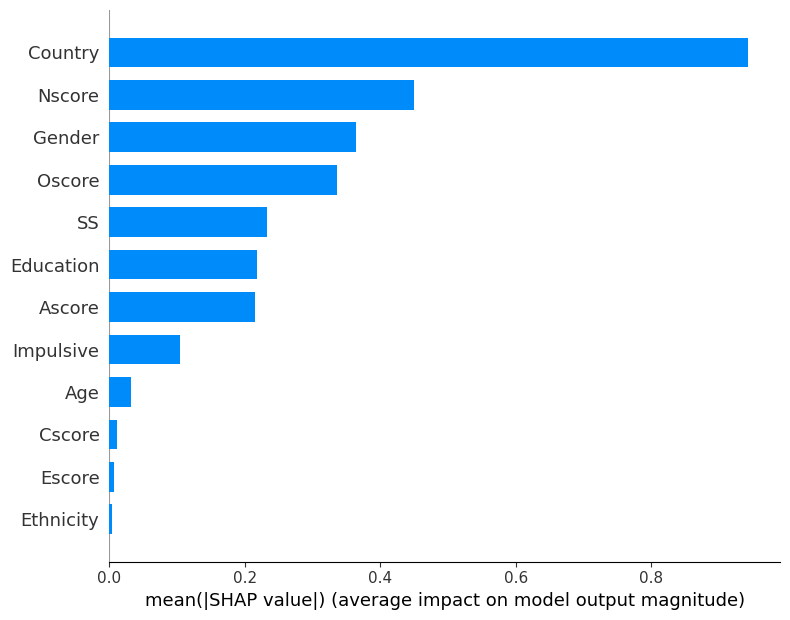

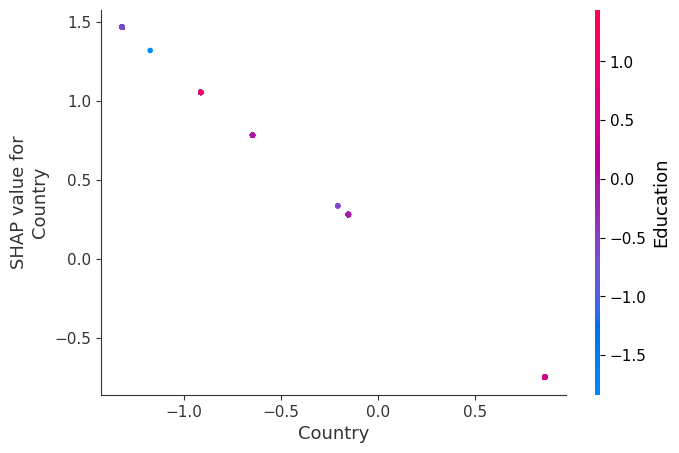


 Kendall tau, LightGBM SHAP vs Logistic SHAP ranking: 1.000

 SHAP rank per fold (1 = most important):
       Age  Gender  Education  Country  Ethnicity  Nscore  Escore  Oscore  Ascore  Cscore  Impulsive  SS
fold1    7       8          2        1         12       4      10       3       9      11          6   5
fold2    3       9          5        1         12       4      11       2       8      10          6   7
fold3    2       9          4        1         12       6      11       7       8      10          3   5
fold4    5       8          2        1         12       7      10       4       9      11          6   3
fold5    4       8          3        1         12       7      10       2       9      11          5   6

 Rank mean / SD across folds:
           mean_rank  sd_rank
Country          1.0     0.00
Education        3.2     1.30
Oscore           3.6     2.07
Age              4.2     1.92
Impulsive        5.2     1.30
SS               5.2     1.48
Nscore           5.6     

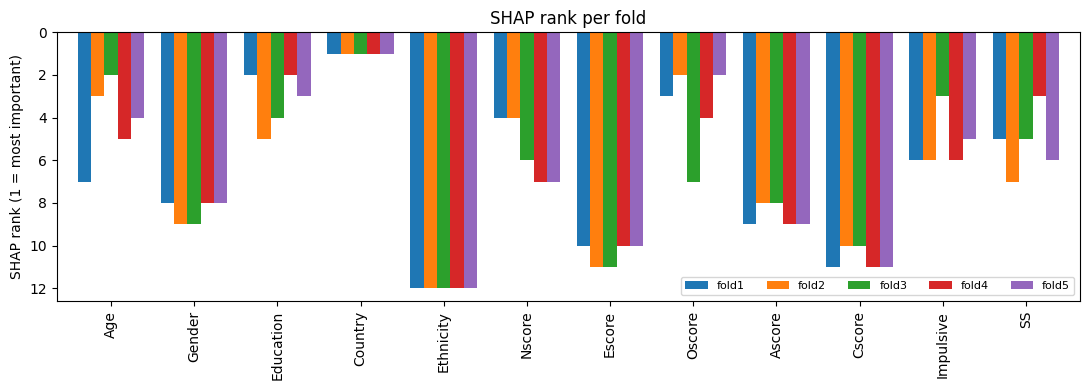


 SHAP rank vs permutation-importance rank:
           shap_rank  perm_rank
Country          1.0        1.0
Oscore           2.0        4.0
Education        3.0        5.0
Nscore           4.0        3.0
Age              5.0        2.0
SS               6.0        7.0
Impulsive        7.0        9.0
Ascore           8.0        8.0
Gender           9.0       10.0
Cscore          10.0        6.0
Escore          11.0       11.0
Ethnicity       12.0       12.0
 Kendall tau (SHAP vs permutation): 0.182


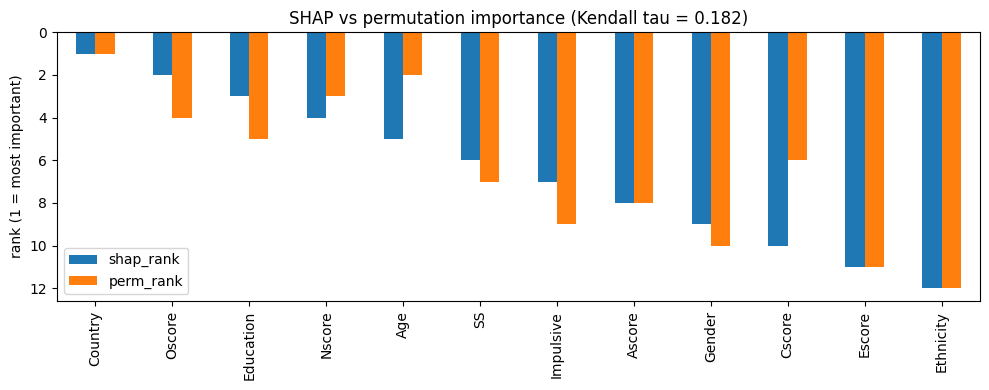

In [ ]:
# Cell 2 — পুরো code
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from scipy.stats import kendalltau
import warnings

warnings.filterwarnings('ignore')
RANDOM_STATE = 42

FEATURES = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity', 'Nscore', 'Escore',
            'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS']


# ---------------------- Data ---------------------- #
def load_data(filename="drug_consumption.csv"):
    df = pd.read_csv(filename)
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    return df[FEATURES], df['target']


def make_lgbm():
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                          num_leaves=15, min_child_samples=20, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                          verbose=-1, random_state=RANDOM_STATE)


# ---------------------- 1. SHAP global ---------------------- #
def shap_global(model, X_test_df, model_type='tree', tag='lgbm'):
    if model_type == 'tree':
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_test_df)
        if isinstance(sv, list):
            sv = sv[1]
    else:
        explainer = shap.LinearExplainer(model, X_test_df)
        sv = explainer.shap_values(X_test_df)

    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=X_test_df.columns)
    mean_abs = mean_abs.sort_values(ascending=False)
    print(f"\n SHAP global importance ({tag}) - mean |SHAP|:")
    print(mean_abs.round(4).to_string())

    shap.summary_plot(sv, X_test_df, show=True, max_display=12)
    shap.summary_plot(sv, X_test_df, plot_type='bar', show=True, max_display=12)
    top = mean_abs.index[0]
    shap.dependence_plot(top, sv, X_test_df, show=True)
    return sv, mean_abs


# ---------------------- 2. SHAP local ---------------------- #
def shap_local(model, X_test_df, sv, idx, tag='lgbm'):
    explainer = shap.TreeExplainer(model)
    base = explainer.expected_value
    if isinstance(base, (list, np.ndarray)):
        base = np.array(base).ravel()[-1]
    exp = shap.Explanation(values=sv[idx], base_values=base,
                           data=X_test_df.iloc[idx].values,
                           feature_names=list(X_test_df.columns))
    shap.plots.waterfall(exp, max_display=12, show=True)
    print(f"\n Local SHAP (case {idx}), top drivers:")
    print(pd.Series(sv[idx], index=X_test_df.columns)
          .sort_values(key=abs, ascending=False).head(6).round(4).to_string())


# ---------------------- 3. LIME local ---------------------- #
def lime_local(model, X_train_arr, X_test_df, idx):
    explainer = LimeTabularExplainer(X_train_arr, feature_names=list(X_test_df.columns),
                                     class_names=['Non-user', 'User'],
                                     discretize_continuous=True, random_state=RANDOM_STATE)
    exp = explainer.explain_instance(X_test_df.iloc[idx].values,
                                     model.predict_proba, num_features=8)
    print(f"\n LIME explanation (case {idx}):")
    for feat, weight in exp.as_list():
        print(f"   {feat:35s} {weight:+.4f}")
    exp.as_pyplot_figure()
    plt.tight_layout()
    plt.show()
    exp.show_in_notebook(show_table=True)
    return dict(exp.as_map()[1])


# ---------------------- 4. SHAP stability across folds ---------------------- #
def shap_stability(X, y, n_splits=5):
    cv = StratifiedKFold(n_splits, shuffle=True, random_state=RANDOM_STATE)
    rankings = []
    for k, (tr, te) in enumerate(cv.split(X, y), 1):
        sc = StandardScaler().fit(X.iloc[tr])
        Xtr = pd.DataFrame(sc.transform(X.iloc[tr]), columns=X.columns)
        Xte = pd.DataFrame(sc.transform(X.iloc[te]), columns=X.columns)
        Xr, yr = SMOTE(random_state=RANDOM_STATE).fit_resample(Xtr, y.iloc[tr])
        m = make_lgbm().fit(Xr, yr)
        sv = shap.TreeExplainer(m).shap_values(Xte)
        if isinstance(sv, list):
            sv = sv[1]
        rankings.append(pd.Series(np.abs(sv).mean(axis=0), index=X.columns)
                        .rank(ascending=False))
    R = pd.DataFrame(rankings, index=[f'fold{k}' for k in range(1, n_splits + 1)])
    print("\n SHAP rank per fold (1 = most important):")
    print(R.astype(int).to_string())
    print("\n Rank mean / SD across folds:")
    print(pd.DataFrame({'mean_rank': R.mean(), 'sd_rank': R.std()})
          .sort_values('mean_rank').round(2).to_string())

    taus = [kendalltau(R.iloc[i], R.iloc[j]).correlation
            for i in range(n_splits) for j in range(i + 1, n_splits)]
    print(f"\n Pairwise Kendall tau between folds: mean {np.mean(taus):.3f} (min {np.min(taus):.3f}, max {np.max(taus):.3f})")

    R.T.plot(kind='bar', figsize=(11, 4), width=0.8)
    plt.ylabel('SHAP rank (1 = most important)')
    plt.gca().invert_yaxis()
    plt.title('SHAP rank per fold')
    plt.legend(ncol=5, fontsize=8)
    plt.tight_layout()
    plt.show()
    return R


# ---------------------- 5. Method agreement ---------------------- #
def method_agreement(model, X_test_df, y_test, shap_rank):
    perm = permutation_importance(model, X_test_df, y_test, n_repeats=30,
                                  random_state=RANDOM_STATE, scoring='average_precision')
    perm_rank = pd.Series(perm.importances_mean, index=X_test_df.columns).rank(ascending=False)
    tau = kendalltau(shap_rank, perm_rank).correlation
    comp = pd.DataFrame({'shap_rank': shap_rank, 'perm_rank': perm_rank}).sort_values('shap_rank')
    print("\n SHAP rank vs permutation-importance rank:")
    print(comp.round(1).to_string())
    print(f" Kendall tau (SHAP vs permutation): {tau:.3f}")

    comp.plot(kind='bar', figsize=(10, 4))
    plt.ylabel('rank (1 = most important)')
    plt.gca().invert_yaxis()
    plt.title(f'SHAP vs permutation importance (Kendall tau = {tau:.3f})')
    plt.tight_layout()
    plt.show()


# ---------------------- Main ---------------------- #
def main():
    X, y = load_data()
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20,
                                              random_state=RANDOM_STATE, stratify=y)
    sc = StandardScaler().fit(X_tr)
    X_tr_s = pd.DataFrame(sc.transform(X_tr), columns=FEATURES)
    X_te_s = pd.DataFrame(sc.transform(X_te), columns=FEATURES)
    X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr_s, y_tr)

    lgbm = make_lgbm().fit(X_res, y_res)
    sv, mean_abs = shap_global(lgbm, X_te_s, 'tree', tag='lgbm')

    proba = lgbm.predict_proba(X_te_s)[:, 1]
    idx = int(np.argmax(proba))
    print(f"\n Explaining case {idx}: predicted P(user) = {proba[idx]:.3f}, true label = {y_te.iloc[idx]}")
    shap_local(lgbm, X_te_s, sv, idx, tag='lgbm')
    lime_local(lgbm, X_res.values, X_te_s, idx)

    lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_res, y_res)
    _, mean_abs_lr = shap_global(lr, X_te_s, 'linear', tag='logreg')
    tau_models = kendalltau(mean_abs.rank(ascending=False), mean_abs_lr.rank(ascending=False)).correlation
    print(f"\n Kendall tau, LightGBM SHAP vs Logistic SHAP ranking: {tau_models:.3f}")

    shap_stability(X, y)
    method_agreement(lgbm, X_te_s, y_te, mean_abs.rank(ascending=False))


main()

In [ ]:
# pip install xgboost imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_recall_fscore_support, make_scorer, recall_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def get_models():
    """All six models with library defaults (only random_state fixed for reproducibility)."""
    return {
        'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
        'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(random_state=RANDOM_STATE),
    }

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test, name=""):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"\n==================== {name} ====================")
    print(f" Accuracy: {acc:.4f}")
    print(f" Balanced Accuracy: {bacc:.4f}")
    print(f" ROC-AUC: {auc:.4f}")
    print(f" PR-AUC: {ap:.4f}  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))

    print(" Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")

    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1],
                                                 zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Balanced Acc': bacc, 'ROC-AUC': auc,
            'PR-AUC': ap, 'Prec(1)': p[1], 'Rec(1)': r[1], 'F1(1)': f[1],
            'F1(0)': f[0], 'Macro F1': (f[0] + f[1]) / 2}, model

def show_importance(model, feature_names, name):
    """Coefficients for linear models, feature_importances_ for tree models."""
    if hasattr(model, 'coef_'):
        imp = pd.DataFrame({'coef': model.coef_[0],
                            'odds_ratio': np.exp(model.coef_[0])}, index=feature_names)
        imp = imp.sort_values('coef', key=abs, ascending=False)
    elif hasattr(model, 'feature_importances_'):
        imp = pd.DataFrame({'importance': model.feature_importances_},
                           index=feature_names)
        imp['importance_pct'] = imp['importance'] / imp['importance'].sum()
        imp = imp.sort_values('importance', ascending=False)
    else:
        return                      # GaussianNB / SVC(RBF) have neither
    print(f"\n Feature Importance - {name}:")
    print(imp.round(3).to_string())

# ---------------------- 10-Fold CV (XGBoost only) ---------------------- #
def xgb_cross_validation(X, y, n_splits=10):
    """Stratified k-fold CV for XGBoost. Scaling + SMOTE happen INSIDE each fold,
    so no information from the validation fold leaks into training."""
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')),
    ])
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    scoring = {
        'Accuracy':      'accuracy',
        'Balanced Acc':  'balanced_accuracy',
        'ROC-AUC':       'roc_auc',
        'PR-AUC':        'average_precision',
        'Prec(1)':       'precision',
        'Rec(1)/Sens':   'recall',
        'Specificity':   make_scorer(recall_score, pos_label=0),
        'F1(1)':         'f1',
        'Macro F1':      'f1_macro',
    }

    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)

    # Per-fold table
    fold_df = pd.DataFrame({k: scores[f'test_{k}'] for k in scoring})
    fold_df.index = [f'Fold {i+1}' for i in range(n_splits)]
    print(f"\n==================== XGBoost {n_splits}-Fold CV ====================")
    print(fold_df.round(3).to_string())

    # Mean ± SD
    print("\n Mean ± SD across folds:")
    for col in fold_df.columns:
        print(f"  {col:<14}: {fold_df[col].mean():.4f} ± {fold_df[col].std():.4f}")

    # Pooled out-of-fold predictions -> one confusion matrix over all samples
    y_oof = cross_val_predict(pipe, X, y, cv=cv, n_jobs=-1)
    cm = confusion_matrix(y, y_oof)
    tn, fp, fn, tp = cm.ravel()
    print("\n Pooled out-of-fold Confusion Matrix:")
    print(cm)
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")
    print("\n Pooled Classification Report:")
    print(classification_report(y, y_oof, target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))
    return fold_df

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    # ---- 10-fold CV for XGBoost (raw X: pipeline handles scaling + SMOTE) ----
    xgb_cross_validation(X, y, n_splits=10)

    # ---- Original hold-out evaluation for all six models ----
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"\nAfter SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    results, trained = [], {}
    for name, model in get_models().items():
        res, fitted = train_and_evaluate_model(model, X_train_res, y_train_res,
                                               X_test_s, y_test, name=name)
        results.append(res)
        trained[name] = fitted

    print("\n\n==================== SUMMARY (test set) ====================")
    summary = pd.DataFrame(results).set_index('Model').sort_values('F1(1)',
                                                                  ascending=False)
    print(summary.round(3).to_string())

    for name, model in trained.items():
        show_importance(model, X.columns, name)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12

==================== XGBoost 10-Fold CV ====================
         Accuracy  Balanced Acc  ROC-AUC  PR-AUC  Prec(1)  Rec(1)/Sens  Specificity  F1(1)  Macro F1
Fold 1      0.856         0.586    0.731   0.278    0.312        0.238        0.934  0.270     0.595
Fold 2      0.846         0.518    0.742   0.214    0.167        0.095        0.940  0.121     0.518
Fold 3      0.830         0.530    0.705   0.253    0.176        0.143        0.916  0.158     0.532
Fold 4      0.878         0.619    0.815   0.395    0.429        0.286        0.952  0.343     0.638
Fold 5      0.856         0.607    0.774   0.317    0.333        0.286        0.928  0.308     0.614
Fold 6      0.894         0.607    0.773   0.379    0.556        0.238        0.976  0.333     0.638
Fold 7      0.846         0.518    0.817   0.274    0.167        0.095        0.940  0.121     0.518
Fold 8      0.840         0.514    0.739   0.210    0.143       

In [ ]:
# pip install xgboost imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_recall_fscore_support, make_scorer, recall_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings

warnings.filterwarnings('ignore')

RANDOM_STATE = 42

# ---------------------- Pipeline Steps ---------------------- #
def load_data(filename):
    return pd.read_csv(filename) if filename.endswith(".csv") else pd.read_excel(filename)

def preprocess_data(df):
    """Drop Semeron over-claimers, build binary heroin target, keep clean features."""
    df = df[df['Semer'] == 'CL0'].copy()
    df['target'] = df['Heroin'].isin(['CL2', 'CL3', 'CL4', 'CL5', 'CL6']).astype(int)
    selected_columns = ['Age', 'Gender', 'Education', 'Country', 'Ethnicity',
                        'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore',
                        'Impulsive', 'SS', 'target']
    df = df[selected_columns]
    df = df.dropna(subset=['target'])
    df.fillna(df.mean(numeric_only=True), inplace=True)
    return df

def scale_features(X_train, X_test):
    """Scaler fitted on TRAIN only (fitting on full X leaks test statistics)."""
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test)

def apply_smote(X_train, y_train):
    smote = SMOTE(random_state=RANDOM_STATE)
    return smote.fit_resample(X_train, y_train)

def get_models():
    """All six models with library defaults (only random_state fixed for reproducibility)."""
    return {
        'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
        'SVM (RBF)': SVC(probability=True, random_state=RANDOM_STATE),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(random_state=RANDOM_STATE),
    }

def train_and_evaluate_model(model, X_train, y_train, X_test, y_test, name=""):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bacc = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    ap = average_precision_score(y_test, y_proba)

    print(f"\n==================== {name} ====================")
    print(f" Accuracy: {acc:.4f}")
    print(f" Balanced Accuracy: {bacc:.4f}")
    print(f" ROC-AUC: {auc:.4f}")
    print(f" PR-AUC: {ap:.4f}  (baseline {y_test.mean():.4f})")

    print("\n Classification Report:")
    print(classification_report(y_test, y_pred,
                                target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))

    print(" Confusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    print(cm)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")

    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1],
                                                 zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Balanced Acc': bacc, 'ROC-AUC': auc,
            'PR-AUC': ap, 'Prec(1)': p[1], 'Rec(1)': r[1], 'F1(1)': f[1],
            'F1(0)': f[0], 'Macro F1': (f[0] + f[1]) / 2}, model

def show_importance(model, feature_names, name):
    """Coefficients for linear models, feature_importances_ for tree models."""
    if hasattr(model, 'coef_'):
        imp = pd.DataFrame({'coef': model.coef_[0],
                            'odds_ratio': np.exp(model.coef_[0])}, index=feature_names)
        imp = imp.sort_values('coef', key=abs, ascending=False)
    elif hasattr(model, 'feature_importances_'):
        imp = pd.DataFrame({'importance': model.feature_importances_},
                           index=feature_names)
        imp['importance_pct'] = imp['importance'] / imp['importance'].sum()
        imp = imp.sort_values('importance', ascending=False)
    else:
        return                      # GaussianNB / SVC(RBF) have neither
    print(f"\n Feature Importance - {name}:")
    print(imp.round(3).to_string())

# ---------------------- 10-Fold CV (XGBoost only) ---------------------- #
def xgb_cross_validation(X, y, n_splits=10):
    """Stratified k-fold CV for XGBoost. Scaling + SMOTE happen INSIDE each fold,
    so no information from the validation fold leaks into training."""
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('xgb', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')),
    ])
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)

    scoring = {
        'Accuracy':      'accuracy',
        'Balanced Acc':  'balanced_accuracy',
        'ROC-AUC':       'roc_auc',
        'PR-AUC':        'average_precision',
        'Prec(1)':       'precision',
        'Rec(1)/Sens':   'recall',
        'Specificity':   make_scorer(recall_score, pos_label=0),
        'F1(1)':         'f1',
        'Macro F1':      'f1_macro',
    }

    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)

    # Per-fold table
    fold_df = pd.DataFrame({k: scores[f'test_{k}'] for k in scoring})
    fold_df.index = [f'Fold {i+1}' for i in range(n_splits)]
    print(f"\n==================== XGBoost {n_splits}-Fold CV ====================")
    print(fold_df.round(3).to_string())

    # Mean ± SD
    print("\n Mean ± SD across folds:")
    for col in fold_df.columns:
        print(f"  {col:<14}: {fold_df[col].mean():.4f} ± {fold_df[col].std():.4f}")

    # Pooled out-of-fold predictions -> one confusion matrix over all samples
    y_oof = cross_val_predict(pipe, X, y, cv=cv, n_jobs=-1)
    cm = confusion_matrix(y, y_oof)
    tn, fp, fn, tp = cm.ravel()
    print("\n Pooled out-of-fold Confusion Matrix:")
    print(cm)
    print(f"\n Sensitivity: {tp/(tp+fn):.3f}   Specificity: {tn/(tn+fp):.3f}")
    print("\n Pooled Classification Report:")
    print(classification_report(y, y_oof, target_names=['Non-user (0)', 'User (1)'],
                                digits=3, zero_division=0))

    # ---- Threshold tuning (Youden's J) to balance Sensitivity & Specificity ----
    # Default threshold 0.5 usually gives high specificity but low sensitivity
    # on imbalanced data. The paper reports balanced sens/spec, so we search for
    # the threshold that maximises (Sensitivity + Specificity - 1).
    y_proba = cross_val_predict(pipe, X, y, cv=cv, method='predict_proba',
                                n_jobs=-1)[:, 1]
    best_t, best_j, best_sens, best_spec = 0.5, -1, 0, 0
    for t in np.arange(0.05, 0.95, 0.01):
        pred = (y_proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        sens, spec = tp / (tp + fn), tn / (tn + fp)
        if sens + spec - 1 > best_j:
            best_j, best_t, best_sens, best_spec = sens + spec - 1, t, sens, spec

    y_best = (y_proba >= best_t).astype(int)
    print("\n==================== Threshold-tuned result (out-of-fold) ====================")
    print(f" Best threshold    : {best_t:.2f}")
    print(f" Sensitivity       : {best_sens:.3f}")
    print(f" Specificity       : {best_spec:.3f}")
    print(f" Balanced Accuracy : {(best_sens + best_spec) / 2:.3f}")
    print(f" Accuracy          : {accuracy_score(y, y_best):.3f}")
    print(f" ROC-AUC           : {roc_auc_score(y, y_proba):.3f}")
    print("\n Confusion Matrix at best threshold:")
    print(confusion_matrix(y, y_best))
    print(" Note: threshold chosen on the same out-of-fold predictions, "
          "so these numbers are slightly optimistic.")
    return fold_df

# ---------------------- Main Entry Point ---------------------- #
def main():
    filename = "drug_consumption.csv"     # update path if needed
    df = load_data(filename)
    df = preprocess_data(df)

    X = df.drop(columns=['target'])
    y = df['target']
    print(f"N = {len(df)} | users = {y.sum()} ({y.mean()*100:.1f}%) | "
          f"non-users = {(1-y).sum()} | features = {X.shape[1]}")

    # ---- 10-fold CV for XGBoost (raw X: pipeline handles scaling + SMOTE) ----
    xgb_cross_validation(X, y, n_splits=10)

    # ---- Original hold-out evaluation for all six models ----
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

    X_train_s, X_test_s = scale_features(X_train, X_test)
    X_train_res, y_train_res = apply_smote(X_train_s, y_train)
    print(f"\nAfter SMOTE: train = {len(y_train_res)} "
          f"({int(y_train_res.sum())} users / {int((1-y_train_res).sum())} non-users)")

    results, trained = [], {}
    for name, model in get_models().items():
        res, fitted = train_and_evaluate_model(model, X_train_res, y_train_res,
                                               X_test_s, y_test, name=name)
        results.append(res)
        trained[name] = fitted

    print("\n\n==================== SUMMARY (test set) ====================")
    summary = pd.DataFrame(results).set_index('Model').sort_values('F1(1)',
                                                                  ascending=False)
    print(summary.round(3).to_string())

    for name, model in trained.items():
        show_importance(model, X.columns, name)

if __name__ == "__main__":
    main()

N = 1877 | users = 209 (11.1%) | non-users = 1668 | features = 12

==================== XGBoost 10-Fold CV ====================
         Accuracy  Balanced Acc  ROC-AUC  PR-AUC  Prec(1)  Rec(1)/Sens  Specificity  F1(1)  Macro F1
Fold 1      0.856         0.586    0.731   0.278    0.312        0.238        0.934  0.270     0.595
Fold 2      0.846         0.518    0.742   0.214    0.167        0.095        0.940  0.121     0.518
Fold 3      0.830         0.530    0.705   0.253    0.176        0.143        0.916  0.158     0.532
Fold 4      0.878         0.619    0.815   0.395    0.429        0.286        0.952  0.343     0.638
Fold 5      0.856         0.607    0.774   0.317    0.333        0.286        0.928  0.308     0.614
Fold 6      0.894         0.607    0.773   0.379    0.556        0.238        0.976  0.333     0.638
Fold 7      0.846         0.518    0.817   0.274    0.167        0.095        0.940  0.121     0.518
Fold 8      0.840         0.514    0.739   0.210    0.143       